In [2]:
import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
import matplotlib
import itertools
import random
import math
import os

In [348]:
h, p = sp.symbols("h p")

g = (h-1) * (1 - (1 - (1-p)**((h-1)/p + 1)) / (h-1 + p))

In [352]:
sp.diff(g, p)

(h - 1)*((1 - p)**(1 + (h - 1)/p)*((-1 - (h - 1)/p)/(1 - p) - (h - 1)*log(1 - p)/p**2)/(h + p - 1) + (1 - (1 - p)**(1 + (h - 1)/p))/(h + p - 1)**2)

In [149]:
W, h, p = sp.symbols("W h p")

In [155]:
ev = W*(h-1) * (1 - (1 - (1-p)**((h-1)/p + 1)) / (h-1 + p)) +\
     W*(h-1) * h * (1 - (1 - (1-p)**(h*(h-1)/p + 1)) / (h*(h-1) + p))

In [156]:
ev

W*h*(h - 1)*(-(1 - (1 - p)**(h*(h - 1)/p + 1))/(h*(h - 1) + p) + 1) + W*(h - 1)*(-(1 - (1 - p)**(1 + (h - 1)/p))/(h + p - 1) + 1)

In [164]:
ev.evalf(subs = {"W": 1, "p": 1e-5, "h": 2}), ev.evalf(subs = {"W": 1, "p": 1, "h": 2})

(1.50321714404584, 1.83333333333333)

In [135]:
-ev_inv_zi1.evalf(subs = {"p": 1e-5, "h": 5})

-0.245420614092352

In [113]:
-ev_inv_zi1.evalf(subs = {"p": 1, "h": 5})

-0.200000000000000

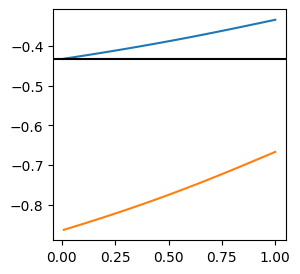

In [226]:
h = 3

fig, ax = plt.subplots(1, 1, figsize = (3, 3))
ox = np.linspace(1e-2, 1, 20)
ax.plot(ox, [-ev_inv_zi1.evalf(subs = {"p": p, "h": h}) for p in ox])
ax.axhline(-(1 - math.exp(-h+1)) / (h - 1), c = 'k')
ax.plot(ox, [-2*ev_inv_zi1.evalf(subs = {"p": p, "h": h}) for p in ox])

In [91]:
nt = 10**5
W = 1

def f(p, h):
    a = (1 / np.maximum(np.random.binomial(int((h-1) / p), p, size = nt), 1)).mean()
    b = (1 / (h**2 - 1 - np.minimum(np.random.binomial(int((h-1) / p), p, size = nt), h**2 - 2))).mean()
    return W*h * (1-a) + W*h*(h-1) * (1-b)
    # return W*h * (1-a)
    # return W*h*(h-1) * (1-b)

def g(p, h):
    a = (1 / (1 + np.random.binomial(int((h-1) / p), p, size = nt))).mean()
    b = (1 / (1 + np.random.binomial(int(h*(h-1) / p), p, size = nt))).mean()
    return W*h * (1-a) + W*h*(h-1) * (1-b)

def f_normal(std, h, nt):
    # Z = np.random.binomial(int((h-1) / p), p, size = (h**2-1,))
    
    Z = np.minimum(h**2-2, np.maximum(1, np.random.normal(h-1, std, size = (h**2-1, nt))))
    
    a = (1 / Z[:h-1]).mean()
    b = (1 / (h**2-1 - Z[h-1:])).mean()
    
    return W*h * (1-a) + W*h*(h-1) * (1-b)

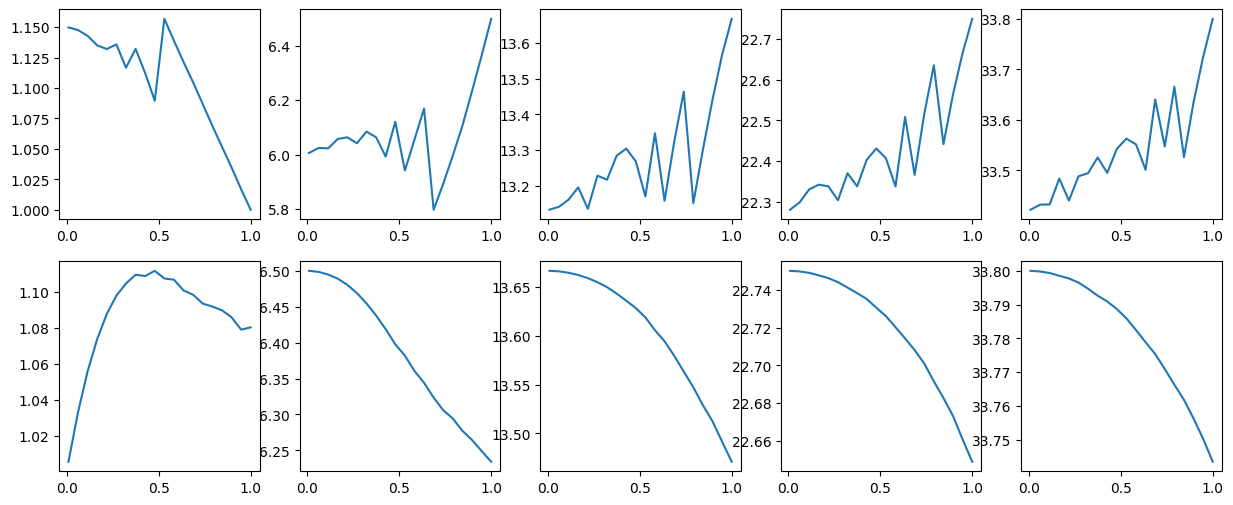

In [93]:
fig, ax = plt.subplots(2, 5, figsize = (3 * 5, 3 * 2))

ox = np.linspace(1e-2, 1, 20)

for i in range(5):
    h = i + 2
    ax[0, i].plot(ox, [f(p, h) for p in ox])
    # ax[1, i].plot(ox, [f_normal(p, h, nt) for p in ox])
    # ax[1, i].plot(ox, [g(p, h) for p in ox])
    # ax[i].axhline(1/(h-1) + h/(h**2-1 - (h-1)), c = 'k')

In [16]:
CONFIG_FOLDER = "/home/vlad/Documents/SublimeMerge/dragonfly-scripts/simulate_dfly_queue_sizes/configs/"

def compute_Z(h, buckets):
    cnt_nodes, cnt_groups, group_size = (h**2 + 1) * h**2, h**2 + 1, h**2
    Z = [[0 for j in range(cnt_groups)] for i in range(cnt_groups)]
    for row in buckets:
        for buck in row:
            for i in range(h):
                for j in range(i+1, h):
                    Z[min(buck[i], buck[j])][max(buck[i], buck[j])] += 1
    return Z

def get_score(h, buckets):
    cnt_nodes, cnt_groups, group_size = (h**2 + 1) * h**2, h**2 + 1, h**2
    Z = compute_Z(h, buckets)
    scor = 0
    for i in range(cnt_groups):
        for j in range(i+1, cnt_groups):
            scor -= abs(Z[i][j] - (h - 1))
    return scor

def build_default_config(h):
    cnt_nodes, cnt_groups, group_size = (h**2 + 1) * h**2, h**2 + 1, h**2
    buckets = [[[] for j in range(h)] for i in range(cnt_groups)]
    for src_group in range(cnt_groups):
        for dst_group in range(cnt_groups):
            if src_group != dst_group:
                src_sw = (dst_group - (1 if src_group < dst_group else 0)) // h
                dst_sw = (src_group - (0 if src_group < dst_group else 1)) // h
                buckets[src_group][src_sw].append(dst_group)
    return buckets

def read_buckets(h, fname):
    make_buckets = lambda v: [[v[j] for j in range(i*h, (i+1)*h)] for i in range(h)]
    with open(fname) as fin:
        return [make_buckets(list(map(int, line.strip().split()))) for line in fin.readlines()]
    
def get_random_buckets(h, nt):
    cnt_groups = h**2 + 1
    
    split_in_buckets = lambda v: [[v[j] for j in range(i, i+h)] for i in range(0, cnt_groups-1, h)]
    
    return [
        [
            split_in_buckets(random.sample(list(range(i)) + list(range(i+1, cnt_groups)), cnt_groups - 1))
            for i in range(cnt_groups)
        ] for _ in range(nt)
    ]

In [19]:
def get_simpd(h, Z):
    cnt_groups = h**2 + 1
    
    simpd_z = (h-1) * (1 - np.mean([
        1/Z[i][j] for i in range(cnt_groups) for j in range(i+1, cnt_groups)
        if Z[i][j] > 0
    ]))
    
    simpd_z_star = h * (h-1) * (1 - np.mean([
            1/(h**2 - 1 - Z[i][j]) for i in range(cnt_groups) for j in range(i+1, cnt_groups)
            if h**2 - 1 - Z[i][j] > 0
        ])
    )
    
    return simpd_z, simpd_z_star

def compute_simplified_dispersion(h, cnt_random_buckets):
    # -E(1/Z) - h(1/Z*). ideal ar descreste cu cat scorul de simetrie este mai bun.
    cnt_nodes, cnt_groups, group_size = (h**2 + 1) * h**2, h**2 + 1, h**2
    k = h * 2

    ht_simpd = {} # Z_score -> [simpds]
    
    arr_buckets = None
    if h <= 4:
        arr_buckets = [
            read_buckets(h, os.path.join(root, file))
            for root, dirs, files in os.walk(CONFIG_FOLDER)
                if dirs == [] and root.endswith(f"_{k}")
                    for file in files
        ]
    else:
        arr_buckets = get_random_buckets(h, cnt_random_buckets)

    for buckets in arr_buckets:        
        score = get_score(h, buckets) # int(file.split('.')[0].split('_')[-1])
        Z = compute_Z(h, buckets)

        if score not in ht_simpd:
            ht_simpd[score] = []
        ht_simpd[score].append(get_simpd(h, Z)) # append tuplu (simpd_z, simpd_star)
    
    return {score: np.mean(ht_simpd[score], axis = 0) for score in sorted(ht_simpd.keys())}

In [23]:
cnt_random_buckets = 10**3

ht_random_scores = {
    h: [get_score(h, buckets) for buckets in get_random_buckets(h, cnt_random_buckets)]
    for h in [2, 3, 4, 6, 8, 10]
}

h = 2, mean Z score = -6.02, std Z score = 2.122
	default_score = -8, default_simpd_Z = 0.222, default_simpd_Z_star = 1.167, min searched simpd = 0.0, max searched simpd = 1.0
h = 3, mean Z score = -41.94, std Z score = 5.714
	default_score = -108, default_simpd_Z = 1.425, default_simpd_Z_star = 5.072, min searched simpd = 0.823, max searched simpd = 5.0
h = 4, mean Z score = -163.224, std Z score = 11.612
	default_score = -576, default_simpd_Z = 2.555, default_simpd_Z_star = 11.036, min searched simpd = 1.474, max searched simpd = 10.999
h = 6, mean Z score = -1082.362, std Z score = 31.48
	default_score = -5400, default_simpd_Z = 4.703, default_simpd_Z_star = 29.022, min searched simpd = 3.689, max searched simpd = 28.996
h = 8, mean Z score = -4091.134, std Z score = 70.579
	default_score = -25088, default_simpd_Z = 6.783, default_simpd_Z_star = 55.023, min searched simpd = 5.794, max searched simpd = 54.998
h = 10, mean Z score = -11418.784, std Z score = 127.162
	default_score = -

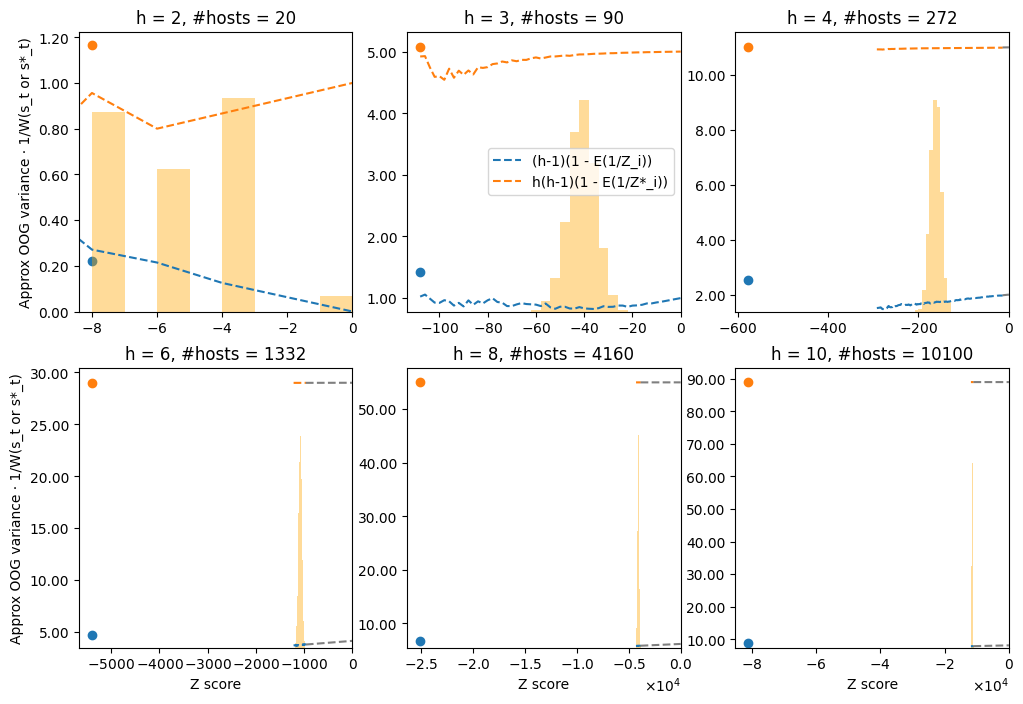

In [36]:
fig, ax = plt.subplots(2, 3, figsize = (3 * 4, 2 * 4))

# for (i, j), h in zip(itertools.product(range(3), range(3)), [2, 3, 4, 6, 8, 10, 12, 14, 16]): # itertools.count(2)
for (i, j), h in zip(itertools.product(range(2), range(3)), [2, 3, 4, 6, 8, 10]):
# for (i, j), h in zip(itertools.product(range(1), range(3)), [2, 3, 4]):
    cnt_nodes, cnt_groups, group_size = (h**2 + 1) * h**2, h**2 + 1, h**2
    
    ht = compute_simplified_dispersion(h, cnt_random_buckets)
    for ind in range(2):
        ax[i, j].plot(
            ht.keys(), [p[ind] for p in ht.values()], ls = "--",
            label = ["(h-1)(1 - E(1/Z_i))", "h(h-1)(1 - E(1/Z*_i))"][ind] if h == 3 else None
        )
    
    if h == 3:
        ax[i, j].legend()

    default_buckets = build_default_config(h)
    default_Z = compute_Z(h, default_buckets)
    
    default_score = get_score(h, default_buckets)
    default_simpd  = get_simpd(h, default_Z)
    ax[i, j].scatter([default_score], [default_simpd[0]])
    ax[i, j].scatter([default_score], [default_simpd[1]])

    random_scores = ht_random_scores[h]
    
    y_base = min([min(p) for p in ht.values()])
    y_base = y_base * (0.95 if y_base > 0 else 1.05)

    ax[i, j].set_ylim([y_base, max(default_simpd) * 1.05])
    ax[i, j].set_xlim([default_score * 1.05, 0])
    hist_height = (max(default_simpd) - y_base) * 0.8

    cnts, lims = np.histogram(random_scores)    
    ax[i, j].stairs(
        y_base + cnts / max(cnts) * hist_height,
        lims,
        fill = True, baseline = y_base, color = "orange", alpha = 0.4
    )
    
    ax[i, j].set_title(f"{h = }, #hosts = {cnt_nodes}")
    
    ax[i, j].yaxis.set_major_formatter(matplotlib.ticker.FormatStrFormatter("%.2f"))
    ax[i, j].ticklabel_format(style='sci', axis='x', scilimits=(-4, 4), useMathText=True)
    
    if h >= 4:
        # nu am atins in cautare Z score = 0 si atunci trag un fit liniar ca sa vad cum ar arata D^2(OOG) estimat
        for ind in range(2):
            m, b = np.polyfit(list(ht.keys()), [p[ind] for p in ht.values()], 1)
            ax[i, j].plot([max(ht.keys()), 0], [max(ht.keys()) * m + b, b], ls = '--', c = 'k', alpha = 0.5)
    
    if i == 1:
        ax[i, j].set_xlabel("Z score")
    if j == 0:
        ax[i, j].set_ylabel("Approx OOG variance ⋅ 1/W(s_t or s*_t)")
            
    print(f"{h = }, mean Z score = {np.mean(random_scores).round(3)}, std Z score = {np.std(random_scores).round(3)}")
    print(f"\t{default_score = }, default_simpd_Z = {round(default_simpd[0], 3)}, default_simpd_Z_star = {round(default_simpd[1], 3)}", end = ", ")
    print(f"min searched simpd = {round(min([min(p) for p in ht.values()]), 3)}, max searched simpd = {round(max([max(p) for p in ht.values()]), 3)}")

fig.savefig(
    "/home/vlad/Desktop/Probleme/LaburiDC/figs_implicit_asymmetry/simplified_oog_variance_against_z_symmetry_v4.pdf",
    bbox_inches = "tight"
)

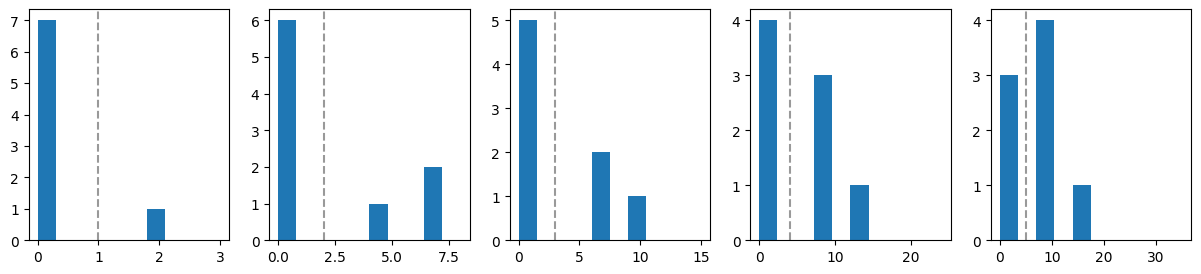

In [251]:
fig, ax = plt.subplots(1, 5, figsize = (3 * 5, 3))

for i, h in enumerate([2, 3, 4, 5, 6]):
    cnt_groups = h**2 + 1
    default_buckets = build_default_config(h)
    Z = compute_Z(h, default_buckets)
    ax[i].hist(*np.histogram([Z[i][j] for i in range(cnt_groups) for j in range(i+1, cnt_groups)]), fill = True)
    ax[i].axvline(h-1, c = 'k', ls = '--', alpha = 0.4)

In [337]:
"""
h = 2, mean Z score = -5.944, std Z score = 2.108
	default_score = -8, default_simpd = 1.389, min searched simpd = 0.992, max searched simpd = 1.227
h = 3, mean Z score = -42.202, std Z score = 5.768
	default_score = -108, default_simpd = 6.497, min searched simpd = 5.454, max searched simpd = 6.0
h = 4, mean Z score = -163.058, std Z score = 12.022
	default_score = -576, default_simpd = 13.59, min searched simpd = 12.42, max searched simpd = 12.98
h = 6, mean Z score = -1081.128, std Z score = 33.068
	default_score = -5400, default_simpd = 33.725, min searched simpd = 32.674, max searched simpd = 32.794
h = 8, mean Z score = -4091.962, std Z score = 72.64
	default_score = -25088, default_simpd = 61.805, min searched simpd = 60.788, max searched simpd = 60.844
h = 10, mean Z score = -11420.72, std Z score = 126.857
	default_score = -81000, default_simpd = 97.855, min searched simpd = 96.853, max searched simpd = 96.876
h = 12, mean Z score = -26339.878, std Z score = 199.756
	default_score = -209088, default_simpd = 141.888, min searched simpd = 140.887, max searched simpd = 140.901
h = 14, mean Z score = -53310.372, std Z score = 294.424
	default_score = -463736, default_simpd = 193.91, min searched simpd = 192.91, max searched simpd = 192.918
h = 16, mean Z score = -98067.71, std Z score = 423.02
	default_score = -921600, default_simpd = 253.927, min searched simpd = 252.924, max searched simpd = 252.929
"""

'\nh = 2, mean Z score = -5.944, std Z score = 2.108\n\tdefault_score = -8, default_simpd = 1.389, min searched simpd = 0.992, max searched simpd = 1.227\nh = 3, mean Z score = -42.202, std Z score = 5.768\n\tdefault_score = -108, default_simpd = 6.497, min searched simpd = 5.454, max searched simpd = 6.0\nh = 4, mean Z score = -163.058, std Z score = 12.022\n\tdefault_score = -576, default_simpd = 13.59, min searched simpd = 12.42, max searched simpd = 12.98\nh = 6, mean Z score = -1081.128, std Z score = 33.068\n\tdefault_score = -5400, default_simpd = 33.725, min searched simpd = 32.674, max searched simpd = 32.794\nh = 8, mean Z score = -4091.962, std Z score = 72.64\n\tdefault_score = -25088, default_simpd = 61.805, min searched simpd = 60.788, max searched simpd = 60.844\nh = 10, mean Z score = -11420.72, std Z score = 126.857\n\tdefault_score = -81000, default_simpd = 97.855, min searched simpd = 96.853, max searched simpd = 96.876\nh = 12, mean Z score = -26339.878, std Z score